# 16e — CNN + inception + LSTM sequence networks (daily model)

An external closing-auction model has three parts:
1. Stacked 1D convolutions that act as learnable smoothing filters while keeping the time resolution.
2. Inception modules that run several kernel sizes in parallel, to learn patterns at different time scales.
3. An LSTM that keeps memory of earlier states.

The original model reads intraday order flow. This notebook tests the same architecture on the **daily** problem: can a network that learns its own filters from each stock's raw daily history beat the hand-built rolling features plus LightGBM? The intraday version is recorded in `reports/intraday_model_ideas.md` for later.

**Adaptation to the daily problem (fixed before running):**
- **Sequence:** for stock-day t, the stock's previous **60 trading days** (t−60 … t−1). Each day has 13 channels:
  - auction volume and daily volume, both in logs relative to the stock's 20-day levels known at t−1
  - auction share
  - return and absolute return
  - six past event flags (month end, quarter end, monthly and quarterly expiry, early close, Friday), so the network can tell an event spike from a genuine surprise
  - a missing-auction flag and a row-present flag (zero padding for stocks with less history)
- **No look-ahead:** each window uses only strictly earlier rows of the same stock. A check below rebuilds `lag1_auction_volume` and `median20_auction_volume` from the windows.
- **Architecture:** conv(13→32, k=5) → conv(32→64, k=5) → inception (bottleneck plus kernels 3/7/15 plus a max-pool branch, 96 channels) → LSTM(64) → last hidden state.
- **Target, rows and folds:** the same residual target, rolling 5-year windows and **identical sampled rows** as LightGBM's large tier in 16a (750K tune / 150K validation / 1M refit). The 16a forecasts are joined row by row.
- **Training:** MSE loss, AdamW (lr 1e-3, weight decay 1e-4), batch 1024 and gradient clipping. Training stops early on the validation year (up to 8 epochs, patience 2), then the model is refitted on the refit window for the best epoch count. This mirrors how LightGBM picks its iteration count. No hyperparameter search is done; one sensible configuration is fixed in advance.

| Candidate | Inputs | Question it answers |
|---|---|---|
| `nn_mlp_tabular` | the 61 LightGBM features, MLP only | Is a neural network on the same features competitive with trees? |
| `nn_cnn_lstm_sequence` | 60-day sequence + target-day calendar only | Can the network learn from raw history what the hand-built features capture? (closest to the source model) |
| `nn_cnn_lstm_hybrid` | 60-day sequence + 61 features | Does the sequence add information beyond the features? |
| `blend_hybrid_lgbm` | 50/50 average (in logs) of the hybrid and `lgbm_61_ratios_large_tuned` | Do the network and the trees make different errors? The weight is fixed in advance, not tuned on test data. |

**Pass rule:** a mean 2022–2024 log RMSE improvement of at least 0.002, no development year worse by more than 0.002, and a paired date-block bootstrap. The main reference is the current best model, `lgbm_61_ratios_large_tuned` (16a); `lgbm_61_ratios_large` and the frozen ridge are secondary references.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display

import challenger_utils as cu
import sequence_utils as su

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")

OUT = cu.output_dir("16e_sequence_neural_networks")
LGBM_16A = cu.EDA / "16a_lightgbm_improvements"  # full-run forecasts, also used in smoke mode
CHAMPION_TREE = "lgbm_61_ratios_large_tuned"
print(f"Outputs: {OUT}; smoke mode: {cu.SMOKE}; device: {su.DEVICE}; torch {torch.__version__}")
print("Training settings:", su.TRAIN)

Outputs: /Users/alisapriyadarsini/Downloads/capstone/blackrock_workspace/outputs/eda/16e_sequence_neural_networks; smoke mode: False; device: mps; torch 2.15.0
Training settings: {'batch': 1024, 'lr': 0.001, 'weight_decay': 0.0001, 'max_epochs': 8, 'patience': 2}


## History windows and the no-look-ahead check

The history store holds every panel row sorted by stock and date. A row's window is the 60 store rows before it, for the same stock only.

In [2]:
store = su.build_history_store()
check_rows = cu.load_period(2019, 2020, 50_000, cu.SEED)
check_index = su.sequence_index(store, check_rows)
windows = su.gather_windows(store, check_index, np.arange(len(check_rows)))
present = windows[:, :, -1] == 1
print(f"History store: {len(store['permno']):,} rows; windows: {windows.shape} (rows, days, channels)")

# 1. Every present window day is strictly before the target day and belongs to the same stock.
position = check_index["position"]
window_pos = np.clip(position[:, None] - np.arange(su.SEQ_LEN, 0, -1), 0, None)
target_dates = np.broadcast_to(store["date"][position][:, None], window_pos.shape)
strictly_earlier = bool((store["date"][window_pos][present] < target_dates[present]).all())
same_stock = bool((store["permno"][window_pos][present] == np.broadcast_to(store["permno"][position][:, None], window_pos.shape)[present]).all())

# 2. The last window day reproduces lag1_auction_volume (same reference level).
lag1 = np.clip(np.log1p(check_rows.lag1_auction_volume.to_numpy(float)) - check_index["ref_auction"], -6, 6)
usable = present[:, -1] & np.isfinite(lag1) & (windows[:, -1, 1] == 0)
lag1_match = float(np.mean(np.abs(windows[usable, -1, 0] - lag1[usable]) < 1e-4))

# 3. The median of the last 20 window days reproduces median20_auction_volume.
last20 = np.expm1(windows[:, -20:, 0] + check_index["ref_auction"][:, None])
complete = present[:, -20:].all(1) & (windows[:, -20:, 1] == 0).all(1) & check_rows.median20_auction_volume.notna().to_numpy()
reference = check_rows.median20_auction_volume.to_numpy(float)
median_match = float(np.mean(np.abs(np.median(last20[complete], axis=1) - reference[complete]) / np.maximum(reference[complete], 1) < 1e-3))

checks = pd.Series({"window days strictly before target": strictly_earlier, "window days same stock": same_stock,
                    "last day == lag1_auction_volume (share)": lag1_match,
                    "median of last 20 == median20_auction_volume (share)": median_match,
                    "rows with full 60-day history (share)": float(present.all(1).mean())})
display(checks.to_frame("value"))
assert strictly_earlier and same_stock and lag1_match > 0.999 and median_match > 0.999

History store: 3,594,404 rows; windows: (50000, 60, 13) (rows, days, channels)


,value
window days strictly before target,True
window days same stock,True
last day == lag1_auction_volume (share),1.0000
median of last 20 == median20_auction_volume (share),1.0000
rows with full 60-day history (share),0.9912


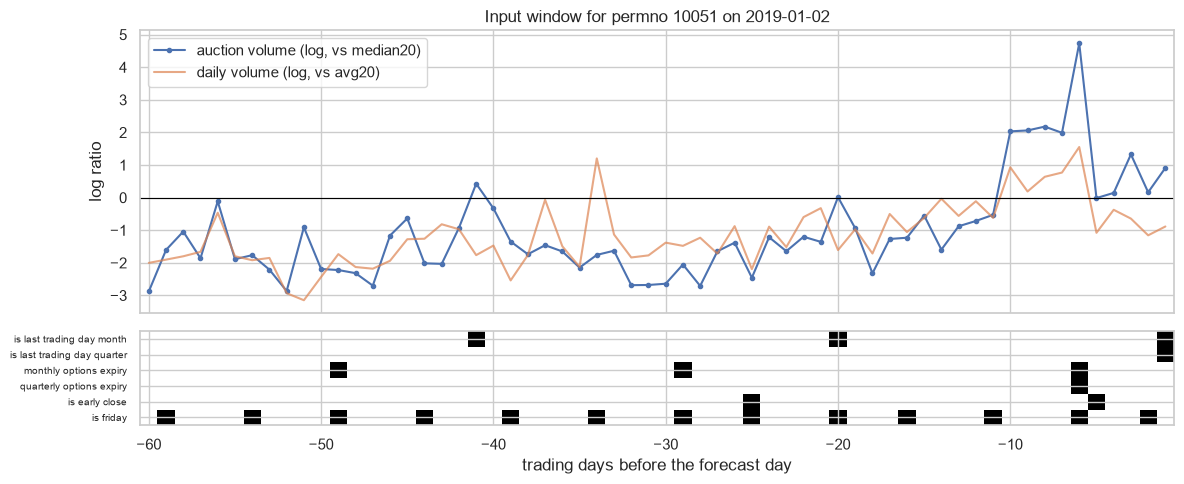

In [3]:
# One example window: what the network sees for a single stock-day.
example = int(np.argmax(present.all(1) & (windows[:, :, 6:12].sum((1, 2)) >= 3)))
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
days = np.arange(-su.SEQ_LEN, 0)
axes[0].plot(days, windows[example, :, 0], marker="o", ms=3, label="auction volume (log, vs median20)")
axes[0].plot(days, windows[example, :, 2], alpha=0.7, label="daily volume (log, vs avg20)")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set(ylabel="log ratio", title=f"Input window for permno {check_rows.permno.iloc[example]} on {check_rows.date.iloc[example]:%Y-%m-%d}")
axes[0].legend()
axes[1].imshow(windows[example, :, 6:12].T, aspect="auto", cmap="Greys", extent=[-su.SEQ_LEN - 0.5, -0.5, 5.5, -0.5])
axes[1].set_yticks(range(6), [f.replace("_", " ") for f in su.EVENT_FLAGS], fontsize=7)
axes[1].set_xlabel("trading days before the forecast day")
plt.tight_layout()
plt.savefig(OUT / "example_input_window.png", bbox_inches="tight")
plt.show()
del windows, check_rows, check_index

## Architectures

In [4]:
tab_dims = {"tabular": 75, "sequence": 30, "hybrid": 75}  # approximate input widths, for the parameter count only
sizes = pd.DataFrame([{"mode": mode, "parameters": su.parameter_count(su.DailyNet(mode, dim))} for mode, dim in tab_dims.items()])
display(sizes)
print(su.DailyNet("hybrid", 75))

,mode,parameters
0,tabular,22209
1,sequence,92409
2,hybrid,98169


DailyNet(
  (seq): SequenceEncoder(
    (convs): Sequential(
      (0): ConvBlock(
        (net): Sequential(
          (0): Conv1d(13, 32, kernel_size=(5,), stride=(1,), padding=(2,))
          (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU()
        )
      )
      (1): ConvBlock(
        (net): Sequential(
          (0): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
          (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU()
        )
      )
    )
    (inception): Inception(
      (bottleneck): Conv1d(64, 24, kernel_size=(1,), stride=(1,))
      (branches): ModuleList(
        (0): Conv1d(24, 24, kernel_size=(3,), stride=(1,), padding=(1,))
        (1): Conv1d(24, 24, kernel_size=(7,), stride=(1,), padding=(3,))
        (2): Conv1d(24, 24, kernel_size=(15,), stride=(1,), padding=(7,))
      )
      (pool): Sequential(
        (0): Ma

## Rolling out-of-time run

About 3–4 hours on an 8 GB M2 (MPS), mostly spent on the two sequence models.

In [5]:
CANDIDATES = [
    {"name": "nn_mlp_tabular", "mode": "tabular"},
    {"name": "nn_cnn_lstm_sequence", "mode": "sequence"},
    {"name": "nn_cnn_lstm_hybrid", "mode": "hybrid"},
]
NAMES = [c["name"] for c in CANDIDATES]
nn_metrics, history = su.run_sequence_experiment(CANDIDATES, store, OUT, "sequence_nn", LGBM_16A, "lgbm_improvements")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[    32s] 2022 rows={'tune': 750000, 'validation': 150000, 'refit': 1000000, 'test': 328634}


[    32s]   nn_mlp_tabular (tabular): tuning


[    37s]       epoch 1: train_mse=0.3896, seconds=3.2597, validation_rmse_log=0.5830


[    40s]       epoch 2: train_mse=0.3651, seconds=2.7971, validation_rmse_log=0.5773


... (150 outputs left out)

[  6965s]       epoch 2: train_mse=0.2354, seconds=155.4969


[  7137s]       epoch 3: train_mse=0.2298, seconds=171.9915


[  7146s]   nn_cnn_lstm_hybrid: test log RMSE 0.4245


[  7148s] wrote 307,853 predictions for 2025


## Results

In [6]:
# Blend the hybrid network with the tuned LightGBM (50/50 in log space; weight fixed in advance).
GLOB = str(OUT / "predictions" / "sequence_nn_predictions_*.parquet")
for year in cu.TEST_YEARS:
    path = OUT / "predictions" / f"sequence_nn_predictions_{year}.parquet"
    frame = cu.sql(f"SELECT * FROM read_parquet('{path}')")
    frame["blend_hybrid_lgbm"] = np.expm1(0.5 * np.log1p(frame["nn_cnn_lstm_hybrid"]) + 0.5 * np.log1p(frame[CHAMPION_TREE]))
    cu.con.register("blended", frame)
    cu.con.execute(f"COPY blended TO '{path}' (FORMAT PARQUET, COMPRESSION ZSTD)")
    cu.con.unregister("blended")
    nn_metrics = pd.concat([nn_metrics, pd.DataFrame([{"test_year": year, "candidate": "blend_hybrid_lgbm", "family": "blend",
        **cu.forecast_metrics(frame["auction_volume"].to_numpy(float), frame["blend_hybrid_lgbm"].to_numpy(float))}])])

m16a = pd.read_csv(LGBM_16A / "candidate_metrics.csv")
m16a = m16a[m16a.candidate.isin([cu.CHAMPION, "lgbm_61_ratios_large", CHAMPION_TREE]) & m16a.test_year.isin(cu.TEST_YEARS)]
metrics = pd.concat([m16a, nn_metrics], ignore_index=True)
metrics.to_csv(OUT / "candidate_metrics.csv", index=False)
ALL = NAMES + ["blend_hybrid_lgbm"]
annual = metrics.pivot_table(index="candidate", columns="test_year", values="rmse_log")
annual["development_mean"] = annual[cu.DEVELOPMENT_YEARS].mean(axis=1)
display(annual.loc[[cu.CHAMPION, "lgbm_61_ratios_large", CHAMPION_TREE] + ALL])

effects = (annual.loc[ALL, cu.TEST_YEARS + ["development_mean"]] - annual.loc[CHAMPION_TREE, cu.TEST_YEARS + ["development_mean"]])
effects.to_csv(OUT / "effects_vs_tuned_lgbm.csv")
print("Change in log RMSE vs the tuned LightGBM (negative = better)")
display(effects)

test_year,2022,2023,2024,2025,development_mean
candidate,,,,,
rolling5_residual_auction_calendar_liquidity,0.5338,0.4838,0.4460,0.4467,0.4879
lgbm_61_ratios_large,0.5060,0.4559,0.4343,0.4236,0.4654
lgbm_61_ratios_large_tuned,0.5025,0.4547,0.4335,0.4242,0.4636
nn_mlp_tabular,0.5050,0.4624,0.4427,0.4249,0.4700
nn_cnn_lstm_sequence,0.5417,0.4703,0.4433,0.4277,0.4851
nn_cnn_lstm_hybrid,0.5253,0.4678,0.4424,0.4245,0.4785
blend_hybrid_lgbm,0.5036,0.4551,0.4312,0.4184,0.4633


Change in log RMSE vs the tuned LightGBM (negative = better)


test_year,2022,2023,2024,2025,development_mean
candidate,,,,,
nn_mlp_tabular,0.0025,0.0077,0.0092,0.0007,0.0065
nn_cnn_lstm_sequence,0.0392,0.0156,0.0098,0.0035,0.0215
nn_cnn_lstm_hybrid,0.0228,0.0132,0.0089,0.0004,0.0150
blend_hybrid_lgbm,0.0011,0.0004,-0.0024,-0.0058,-0.0003


In [7]:
vs_tree, boot_tree = cu.decision_table(metrics, GLOB, CHAMPION_TREE, ALL)
vs_large, _ = cu.decision_table(metrics, GLOB, "lgbm_61_ratios_large", ALL)
vs_ridge, boot_ridge = cu.decision_table(metrics, GLOB, cu.CHAMPION, ALL)
pd.concat([vs_tree, vs_large, vs_ridge]).to_csv(OUT / "candidate_selection.csv", index=False)
pd.concat([boot_tree.assign(reference=CHAMPION_TREE), boot_ridge.assign(reference=cu.CHAMPION)]).to_csv(
    OUT / "date_block_bootstrap.csv", index=False)
print("Against the tuned LightGBM (current best)")
display(vs_tree)
print("Against LightGBM large, default settings (same rows)")
display(vs_large)
print("Against the frozen ridge benchmark")
display(vs_ridge)

Against the tuned LightGBM (current best)


,candidate,reference,development_rmse_log,confirmation_rmse_log,development_wape,rmse_change_vs_reference,worst_year_change,confirmation_change,log_mae_diff,log_mae_ci_97_5,practical_improvement,stable_each_year,paired_significant,passes_gate
0,nn_mlp_tabular,lgbm_61_ratios_large_tuned,0.4700,0.4249,0.3572,0.0065,0.0092,0.0007,0.0054,0.0077,False,False,False,False
1,nn_cnn_lstm_sequence,lgbm_61_ratios_large_tuned,0.4851,0.4277,0.3695,0.0215,0.0392,0.0035,0.0120,0.0185,False,False,False,False
2,nn_cnn_lstm_hybrid,lgbm_61_ratios_large_tuned,0.4785,0.4245,0.3578,0.0150,0.0228,0.0004,0.0073,0.0125,False,False,False,False
3,blend_hybrid_lgbm,lgbm_61_ratios_large_tuned,0.4633,0.4184,0.3485,-0.0003,0.0011,-0.0058,-0.0014,0.0008,False,True,False,False
4,lgbm_61_ratios_large_tuned,lgbm_61_ratios_large_tuned,0.4636,0.4242,0.3488,0.0000,0.0000,0.0000,NaN,NaN,None,None,None,None


Against LightGBM large, default settings (same rows)


,candidate,reference,development_rmse_log,confirmation_rmse_log,development_wape,rmse_change_vs_reference,worst_year_change,confirmation_change,log_mae_diff,log_mae_ci_97_5,practical_improvement,stable_each_year,paired_significant,passes_gate
0,nn_mlp_tabular,lgbm_61_ratios_large,0.4700,0.4249,0.3572,0.0046,0.0083,0.0012,0.0034,0.0059,False,False,False,False
1,nn_cnn_lstm_sequence,lgbm_61_ratios_large,0.4851,0.4277,0.3695,0.0197,0.0357,0.0041,0.0101,0.0168,False,False,False,False
2,nn_cnn_lstm_hybrid,lgbm_61_ratios_large,0.4785,0.4245,0.3578,0.0131,0.0193,0.0009,0.0054,0.0107,False,False,False,False
3,blend_hybrid_lgbm,lgbm_61_ratios_large,0.4633,0.4184,0.3485,-0.0021,-0.0008,-0.0052,-0.0034,-0.0013,True,True,True,True
4,lgbm_61_ratios_large,lgbm_61_ratios_large,0.4654,0.4236,0.3507,0.0000,0.0000,0.0000,NaN,NaN,None,None,None,None


Against the frozen ridge benchmark


,candidate,reference,development_rmse_log,confirmation_rmse_log,development_wape,rmse_change_vs_reference,worst_year_change,confirmation_change,log_mae_diff,log_mae_ci_97_5,practical_improvement,stable_each_year,paired_significant,passes_gate
0,nn_mlp_tabular,rolling5_residual_auction_calendar_liquidity,0.4700,0.4249,0.3572,-0.0178,-0.0034,-0.0218,-0.0065,-0.0023,True,True,True,True
1,nn_cnn_lstm_sequence,rolling5_residual_auction_calendar_liquidity,0.4851,0.4277,0.3695,-0.0028,0.0079,-0.0189,0.0001,0.0068,True,False,False,False
2,nn_cnn_lstm_hybrid,rolling5_residual_auction_calendar_liquidity,0.4785,0.4245,0.3578,-0.0093,-0.0036,-0.0221,-0.0046,0.0003,True,True,False,False
3,blend_hybrid_lgbm,rolling5_residual_auction_calendar_liquidity,0.4633,0.4184,0.3485,-0.0246,-0.0149,-0.0283,-0.0134,-0.0092,True,True,True,True
4,rolling5_residual_auction_calendar_liquidity,rolling5_residual_auction_calendar_liquidity,0.4879,0.4467,0.3674,0.0000,0.0000,0.0000,NaN,NaN,None,None,None,None


In [8]:
# Do the networks make different errors from the trees? (log errors, development years)
errors = cu.sql(f"""
    SELECT year(date) AS test_year,
           {", ".join(f'ln(1 + "{c}") - log1p_auction_volume AS "{c}"' for c in [CHAMPION_TREE, "lgbm_61_ratios_large"] + NAMES)}
    FROM read_parquet('{GLOB}') WHERE year(date) IN ({", ".join(map(str, cu.DEVELOPMENT_YEARS))})
""")
correlation = errors.drop(columns="test_year").corr()
correlation.to_csv(OUT / "error_correlation.csv")
display(correlation)

segments = cu.segment_table(GLOB, [CHAMPION_TREE] + ALL)
segments.to_csv(OUT / "segment_rmse.csv")
display(segments)

,lgbm_61_ratios_large_tuned,lgbm_61_ratios_large,nn_mlp_tabular,nn_cnn_lstm_sequence,nn_cnn_lstm_hybrid
lgbm_61_ratios_large_tuned,1.0000,0.9919,0.9607,0.9097,0.9339
lgbm_61_ratios_large,0.9919,1.0000,0.9595,0.9104,0.9331
nn_mlp_tabular,0.9607,0.9595,1.0000,0.9015,0.9269
nn_cnn_lstm_sequence,0.9097,0.9104,0.9015,1.0000,0.9505
nn_cnn_lstm_hybrid,0.9339,0.9331,0.9269,0.9505,1.0000


candidate                     blend_hybrid_lgbm  lgbm_61_ratios_large_tuned  \
dimension   segment                                                           
actual_tail lower_99pct                  0.4523                      0.4538   
            top_1pct                     1.1630                      1.1094   
event       month_end                    0.6403                      0.6479   
            monthly_expiry               0.5406                      0.5402   
            quarterly_expiry             0.7667                      0.7591   
            regular                      0.4432                      0.4431   
size        large                        0.3923                      0.3926   
            mid                          0.4274                      0.4268   
            small                        0.5706                      0.5713   

candidate                     nn_cnn_lstm_hybrid  nn_cnn_lstm_sequence  \
dimension   segment                                                      
actual_tail lower_99pct                   0.4663                0.4743   
            top_1pct                      1.2450                1.2236   
event       month_end                     0.6515                0.6648   
            monthly_expiry                0.5489                0.5436   
            quarterly_expiry              0.8106                0.8477   
            regular                       0.4587                0.4651   
size        large                         0.4044                0.4117   
            mid                           0.4422                0.4480   
            small                         0.5902                0.5987   

candidate                     nn_mlp_tabular  
dimension   segment                           
actual_tail lower_99pct               0.4606  
            top_1pct                  1.0959  
event       month_end                 0.6870  
            monthly_expiry            0.5469  
            quarterly_expiry          0.7706  
            regular                   0.4466  
size        large                     0.3985  
            mid                       0.4332  
            small                     0.5780

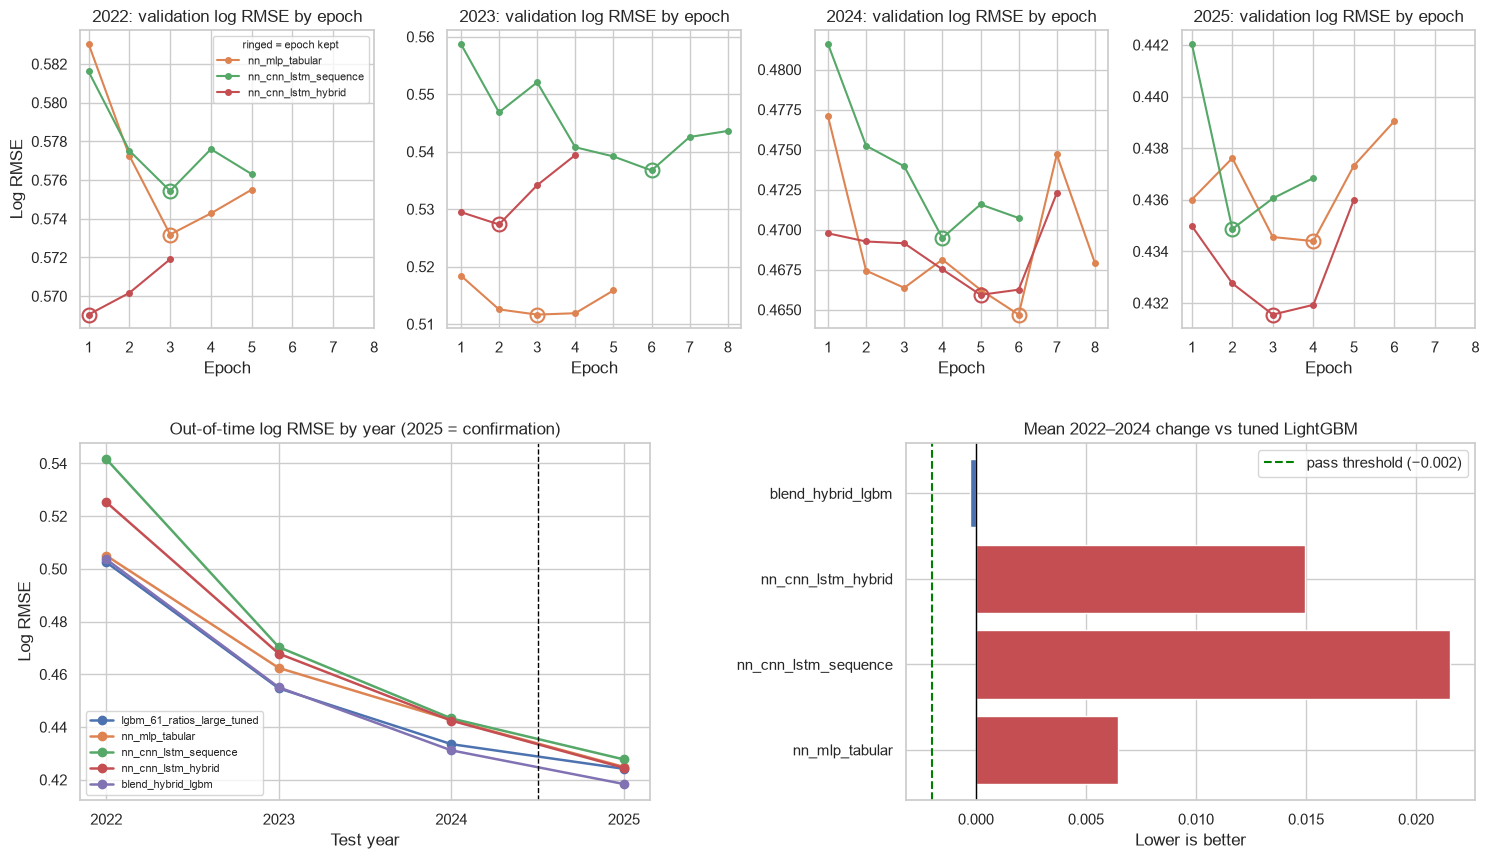

Epochs chosen on the validation year


test_year,2022,2023,2024,2025
candidate,,,,
nn_cnn_lstm_hybrid,1.0000,2.0000,5.0000,3.0000
nn_cnn_lstm_sequence,3.0000,6.0000,4.0000,2.0000
nn_mlp_tabular,3.0000,3.0000,6.0000,4.0000


In [9]:
fig = plt.figure(figsize=(18, 10))
grid = fig.add_gridspec(2, 1, height_ratios=[1, 1.2], hspace=0.35)
top = grid[0].subgridspec(1, len(cu.TEST_YEARS), wspace=0.25)
bottom = grid[1].subgridspec(1, 2, wspace=0.45)
colors = dict(zip([CHAMPION_TREE] + ALL, sns.color_palette(n_colors=len(ALL) + 1)))

# One panel per test year: validation log RMSE by epoch in the tuning phase; the ringed point is the epoch kept.
curves = history[history.phase == "tune"]
for i, year in enumerate(cu.TEST_YEARS):
    ax = fig.add_subplot(top[0, i])
    for name in NAMES:
        c = curves[(curves.test_year == year) & (curves.candidate == name)]
        ax.plot(c.epoch, c.validation_rmse_log, marker="o", ms=4, lw=1.5, color=colors[name], label=name)
        best = c.loc[c.validation_rmse_log.idxmin()]
        ax.plot(best.epoch, best.validation_rmse_log, "o", ms=10, mfc="none", mec=colors[name], mew=1.5)
    ax.set_xticks(range(1, int(curves.epoch.max()) + 1))
    ax.set(title=f"{year}: validation log RMSE by epoch", xlabel="Epoch", ylabel="Log RMSE" if i == 0 else None)
    if i == 0:
        ax.legend(fontsize=8, title="ringed = epoch kept", title_fontsize=8)

ax = fig.add_subplot(bottom[0, 0])
plot = metrics[metrics.candidate.isin([CHAMPION_TREE] + ALL)]
for name in [CHAMPION_TREE] + ALL:
    p = plot[plot.candidate == name].sort_values("test_year")
    ax.plot(p.test_year, p.rmse_log, marker="o", lw=1.8, color=colors[name], label=name)
ax.axvline(cu.TEST_YEARS[-1] - 0.5, color="black", ls="--", lw=1)
ax.set_xticks(cu.TEST_YEARS)
ax.set(title="Out-of-time log RMSE by year (2025 = confirmation)", xlabel="Test year", ylabel="Log RMSE")
ax.legend(fontsize=8)

ax = fig.add_subplot(bottom[0, 1])
bars = effects["development_mean"]
ax.barh(bars.index, bars.values, color=["#4c72b0" if v < 0 else "#c44e52" for v in bars.values])
ax.axvline(-0.002, color="green", ls="--", label="pass threshold (−0.002)")
ax.axvline(0, color="black", lw=1)
ax.set(title="Mean 2022–2024 change vs tuned LightGBM", xlabel="Lower is better")
ax.legend()
plt.savefig(OUT / "sequence_nn_results.png", bbox_inches="tight")
plt.show()

epochs_used = nn_metrics[nn_metrics.candidate.isin(NAMES)].pivot_table(index="candidate", columns="test_year", values="iterations")
print("Epochs chosen on the validation year")
display(epochs_used)

## Conclusion data

In [10]:
summary = {
    "development_rmse_log": annual.loc[[cu.CHAMPION, "lgbm_61_ratios_large", CHAMPION_TREE] + ALL, "development_mean"].round(5).to_dict(),
    "confirmation_rmse_log": annual.loc[[cu.CHAMPION, "lgbm_61_ratios_large", CHAMPION_TREE] + ALL, cu.CONFIRMATION_YEAR].round(5).to_dict(),
    "mean_development_change_vs_tuned_lgbm": effects["development_mean"].round(5).to_dict(),
    "passes_gate_vs_tuned_lgbm": vs_tree.loc[vs_tree.passes_gate == True, "candidate"].tolist(),
    "passes_gate_vs_frozen_ridge": vs_ridge.loc[vs_ridge.passes_gate == True, "candidate"].tolist(),
    "error_correlation_hybrid_vs_tuned_lgbm": round(float(correlation.loc["nn_cnn_lstm_hybrid", CHAMPION_TREE]), 4),
    "training": su.TRAIN, "sequence_length": su.SEQ_LEN, "channels": su.CHANNELS,
    "smoke_mode": cu.SMOKE,
}
with open(OUT / "summary.json", "w") as handle:
    json.dump(summary, handle, indent=2, default=str)
display(summary)

{'development_rmse_log': {'rolling5_residual_auction_calendar_liquidity': 0.48788,
  'lgbm_61_ratios_large': 0.46541,
  'lgbm_61_ratios_large_tuned': 0.46357,
  'nn_mlp_tabular': 0.47004,
  'nn_cnn_lstm_sequence': 0.48509,
  'nn_cnn_lstm_hybrid': 0.47854,
  'blend_hybrid_lgbm': 0.4633},
 'confirmation_rmse_log': {'rolling5_residual_auction_calendar_liquidity': 0.44665,
  'lgbm_61_ratios_large': 0.42363,
  'lgbm_61_ratios_large_tuned': 0.42417,
  'nn_mlp_tabular': 0.42488,
  'nn_cnn_lstm_sequence': 0.42772,
  'nn_cnn_lstm_hybrid': 0.42452,
  'blend_hybrid_lgbm': 0.41839},
 'mean_development_change_vs_tuned_lgbm': {'nn_mlp_tabular': 0.00647,
  'nn_cnn_lstm_sequence': 0.02152,
  'nn_cnn_lstm_hybrid': 0.01497,
  'blend_hybrid_lgbm': -0.00027},
 'passes_gate_vs_tuned_lgbm': [],
 'passes_gate_vs_frozen_ridge': ['nn_mlp_tabular', 'blend_hybrid_lgbm'],
 'error_correlation_hybrid_vs_tuned_lgbm': 0.9339,
 'training': {'batch': 1024,
  'lr': 0.001,
  'weight_decay': 0.0001,
  'max_epochs': 8,
  '

## Conclusion

Figures are from the full run (4 rolling folds, the same rows as the 16a large tier). A change is new log RMSE minus `lgbm_61_ratios_large_tuned` log RMSE, so **negative means better**.

| Candidate | Development log RMSE | Change vs tuned LightGBM | 2025 change | Error correlation with LightGBM | Passes vs tuned LightGBM |
|---|---|---|---|---|---|
| `lgbm_61_ratios_large_tuned` (reference) | 0.4636 | — | — | 1.00 | — |
| `nn_mlp_tabular` | 0.4700 | +0.0065 | +0.0007 | 0.96 | no |
| `nn_cnn_lstm_sequence` | 0.4851 | +0.0215 | +0.0035 | 0.91 | no |
| `nn_cnn_lstm_hybrid` | 0.4785 | +0.0150 | +0.0004 | 0.93 | no |
| `blend_hybrid_lgbm` (50/50) | 0.4633 | −0.0003 | **−0.0058** | — | no (passes vs untuned `lgbm_61_ratios_large`) |

**1. The CNN + inception + LSTM does not beat LightGBM on the daily problem.**
- The sequence-only network learns a lot from raw history alone: it reaches 0.4851, slightly better than the frozen ridge (0.4879), using no hand-built features. But it is 0.022 behind LightGBM.
- The 60-day rolling features (lags, 5/20/60-day averages and medians, ratios) already capture the useful shape of daily history.

**2. The sequence branch adds noise, not information.**
- The hybrid (sequence + 61 features) is *worse* than the plain MLP on the same 61 features (0.4785 vs 0.4700).
- Training error keeps falling while validation error bottoms out after 1–5 epochs and swings by about ±0.005 from epoch to epoch. The roughly 98K-parameter sequence encoder overfits quickly, and early stopping on a noisy validation year adds variance.

**3. Neural networks and trees make partly different errors, but the networks are too weak for that to matter.**
- Error correlation with LightGBM is 0.91–0.96, lower than CatBoost's 0.985.
- The fixed 50/50 blend gains 0.006 in 2025 and passes the gate against default-settings LightGBM. Against the tuned champion, the development-year gain is only 0.0003, far below the 0.002 rule.

**4. By segment:**
- The networks are worse on quarterly expiry and month-end days.
- The MLP is slightly better than LightGBM on the top 1% of volumes (1.096 vs 1.109 log RMSE). That is the only segment where a network leads.

**Decision:** do not replace or blend into the champion. `lgbm_61_ratios_large_tuned` stays.

The architecture is better suited to intraday order flow, where no hand-built daily summary exists; see `reports/intraday_model_ideas.md`.

If neural networks are revisited for the daily model, the cheapest next steps are:
- averaging several seeds, to cut the epoch-to-epoch variance
- a learning-rate schedule with stronger regularisation
- a blend weight chosen on the validation year rather than fixed at 50/50

None of these is likely to close a 0.0065 gap on its own.